# Short-List Promising Models & Fine-Tune the System

Short-list checklist:
1. Train a bunch of quick models w/ default params
2. Compare them (CV mean + std)
3. Most important features
4. What kinds of errors they make
5. Any quick feature changes? (actually do them in Preparation)
6. Pick top 3 - ideally ones that make different mistakes

### Imports

In [1]:
%load_ext autoreload
%autoreload 2

import json
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier, VotingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report, confusion_matrix,
                             fbeta_score, make_scorer, precision_score, recall_score)
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold, cross_val_predict, cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from custom_transformers import *

from sklearn import set_config
set_config(transform_output="pandas")

### Load data + preprocessor

In [2]:
TARGET_COL = "is_diseased"

train_set = pd.read_parquet("train_set.parquet")
X = train_set.drop(columns=TARGET_COL)
y = train_set[TARGET_COL].copy()
groups = train_set["Unique Squirrel ID"]   # same squirrel stays in one fold

with open("preprocessor.pkl", "rb") as f:
    preprocessor = pickle.load(f)

X_prepared = preprocessor.transform(X)
X_prepared.shape

(2418, 46)

In [3]:
# grouped + stratified folds, same idea as our train/test split
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# F2 = recall counts more than precision
f2 = make_scorer(fbeta_score, beta=2)
SCORING = {"f2": f2, "recall": "recall", "precision": "precision", "avg_precision": "average_precision"}
MAIN_METRIC = "f2"

RANDOM_STATE = 42

## Short-List Models

In [4]:
# default params on purpose (quick and dirty)
base_models = {
    "logreg": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "rf": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "hgb": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    "svc": SVC(random_state=RANDOM_STATE),
    "knn": KNeighborsClassifier(),
    "nb": GaussianNB(),
    "mlp": MLPClassifier(max_iter=1000, random_state=RANDOM_STATE),
}

rows = []
for name, model in base_models.items():
    scores = cross_validate(model, X_prepared, y, groups=groups, cv=cv, scoring=SCORING)
    row = {"model": name}
    for metric in SCORING:
        row[metric] = scores[f"test_{metric}"].mean()
        row[f"{metric}_std"] = scores[f"test_{metric}"].std()
    rows.append(row)

shortlist_results = pd.DataFrame(rows).set_index("model").sort_values(MAIN_METRIC, ascending=False)
shortlist_results.round(3)

,f2,f2_std,recall,recall_std,precision,precision_std,avg_precision,avg_precision_std
model,,,,,,,,
nb,0.537,0.119,0.659,0.177,0.349,0.080,0.447,0.071
logreg,0.486,0.068,0.459,0.074,0.653,0.041,0.575,0.045
hgb,0.448,0.057,0.423,0.057,0.593,0.050,0.555,0.043
mlp,0.438,0.066,0.423,0.067,0.519,0.062,0.486,0.046
rf,0.434,0.066,0.403,0.064,0.628,0.066,0.543,0.057
tree,0.387,0.031,0.386,0.036,0.396,0.044,0.230,0.020
svc,0.379,0.047,0.340,0.046,0.709,0.036,0.579,0.047
knn,0.176,0.053,0.149,0.046,0.702,0.061,0.288,0.040


- Naive bayes comes out on top for F2, but mostly because it guesses sick a lot (recall 0.66, precision 0.35). It also has by far the biggest std (0.119), so it's pretty unstable between folds.
- Logreg and hgb are more balanced, they're more precise but only catch around 42-46% of the sick squirrels. That's way too low for what the client wants.
- Tree and knn are the worst. Knn basically just predicts healthy for almost everything (recall 0.15).
- The defaults don't know only ~12.5% are sick, so most of them lean towards predicting healthy. We tune `class_weight` below, so recall should go up a lot.

Going forward we picked the top 3 by F2: nb, logreg and hgb. It's a nice mix too, one probabilistic, one linear and one tree based.

### Errors

In [5]:
# our top 3 picks - change this list if we want different ones
SHORTLIST = list(shortlist_results.index[:3])
SHORTLIST

['nb', 'logreg', 'hgb']

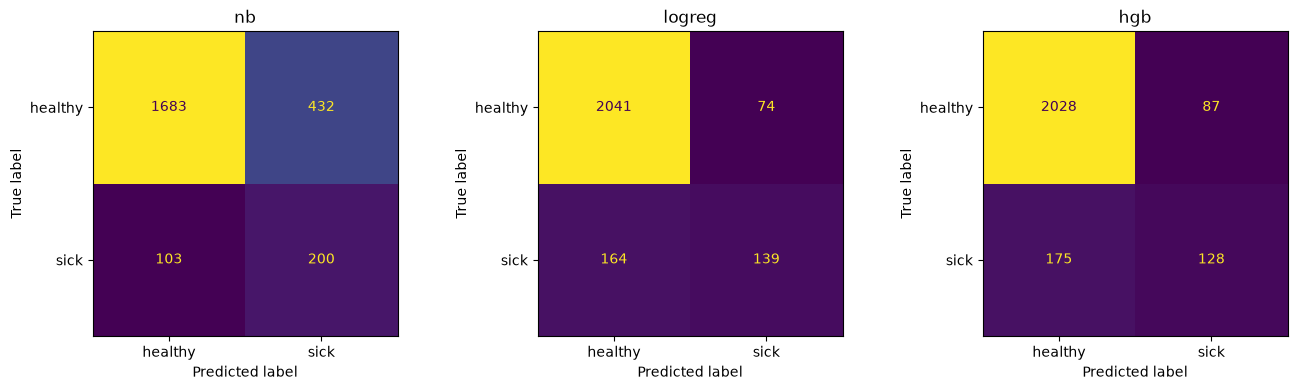

In [6]:
# out-of-fold predictions so every row is predicted by a model that didn't train on it
oof_preds = {
    name: cross_val_predict(base_models[name], X_prepared, y, groups=groups, cv=cv)
    for name in SHORTLIST
}

fig, axes = plt.subplots(1, len(SHORTLIST), figsize=(4.5 * len(SHORTLIST), 4))
for ax, name in zip(np.atleast_1d(axes), SHORTLIST):
    ConfusionMatrixDisplay.from_predictions(y, oof_preds[name], display_labels=["healthy", "sick"],
                                            colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [7]:
# do they miss the same sick squirrels? (low overlap = good for an ensemble)
missed = {name: set(np.where((y.values == 1) & (pred == 0))[0]) for name, pred in oof_preds.items()}
overlap = pd.DataFrame(
    [[len(missed[a] & missed[b]) for b in SHORTLIST] for a in SHORTLIST],
    index=SHORTLIST, columns=SHORTLIST,
)
print("sick squirrels missed (diagonal) and missed by both (off-diagonal):")
overlap

sick squirrels missed (diagonal) and missed by both (off-diagonal):


,nb,logreg,hgb
nb,103,93,90
logreg,93,164,145
hgb,90,145,175


- Out of the ~300 sick squirrels, nb misses 103, logreg misses 164 and hgb misses 175. nb catches the most, but it also gives way more false alarms than the other two.
- Logreg and hgb miss mostly the same squirrels (145 in common), so they're making pretty similar mistakes.
- nb is the most different. hgb misses about 85 squirrels that nb catches, so nb might be useful to have in an ensemble.

There are still up to 90 sick squirrels that all 3 miss. We should probably look at those to see if they have anything in common.

### Important Features

In [8]:
# permutation importance: how much F2 drops when a feature gets shuffled
# (on training data, so just a rough look)
importances = {}
for name in SHORTLIST:
    model = clone(base_models[name]).fit(X_prepared, y)
    result = permutation_importance(model, X_prepared, y, scoring=f2, n_repeats=5,
                                    random_state=RANDOM_STATE, n_jobs=-1)
    importances[name] = pd.Series(result.importances_mean, index=X_prepared.columns)

importance_table = pd.DataFrame(importances)
importance_table.loc[importance_table.mean(axis=1).sort_values(ascending=False).index].head(20).round(4)

,nb,logreg,hgb
categorical__Primary Fur Color_Gray,0.1958,0.4006,0.5437
categorical__Primary Fur Color_Cinnamon,0.2067,0.1861,0.0056
categorical__Primary Fur Color_Black,0.1009,0.1462,0.0026
weather__shift_temp_c,0.0096,0.0256,0.1743
hectare__hectare_row,-0.0008,0.0340,0.1114
activity__Climbing,0.0061,0.0229,0.0629
counts__Hectare Squirrel Number,-0.0013,0.0020,0.0884
counts__Number of Squirrels,-0.0042,0.0029,0.0803
activity__Running,0.0010,0.0199,0.0573
interaction__Runs from,0.0038,0.0335,0.0380


- Fur color is by far the most important for all 3 models, which lines up with exploration. Gray being the top one makes sense since it basically tells the model "probably healthy".
- hgb leans a lot more on temperature, hectare row and the squirrel counts. Now that X/Y are gone, hectare row seems to have taken over for location. This is on the training data though, so some of that might just be hgb memorizing.
- `Running`, `Runs from` and `Climbing` show up too, which also matches what we saw in exploration.
- `Approaches` barely makes the top 20, even though it was our biggest behavior signal in exploration. Probably because only ~5% of squirrels have it checked.

For quick feature changes, after the first round of tuning we went back and dropped X/Y, `any_vocalization` and the "looking at me" anchor in Preparation, since all 3 models dropped them. This round all 3 dropped `Litter`, so that might be the next one to go.

# Fine-Tune the System

Fine-tune checklist:
1. Tune each shortlisted model w/ CV - 10+ hyperparameters, some preprocessing + some model
2. Try an ensemble
3. Check the final model on the test set (only once!)

In [9]:
N_ITER = 30   # random combos per search
N_JOBS = 4    # each worker loads spaCy, so don't go too high

# original (unfitted) pieces of our preprocessor, by name
pre_parts = {name: part for name, part, cols in preprocessor.transformers}
activity_anchors = list(pre_parts["activity_text"].concepts)
interaction_anchors = list(pre_parts["interaction_text"].concepts)

# preprocessing hyperparameters shared by every search
PREP_PARAMS = {
    "preprocessor__activity_text__concepts": [
        activity_anchors,
        [a for a in activity_anchors if a != "running"],       # overlap w/ "runs away"?
    ],
    "preprocessor__interaction_text__concepts": [
        interaction_anchors,
        [a for a in interaction_anchors if a != "dog"],         # dog = context, not symptom?
    ],
    "preprocessor__interaction__merge_none_into_indifferent": [True, False],
    "preprocessor__vocal__any_flag_name": [None, "any_vocalization"],
    "preprocessor__counts__impute__strategy": ["median", "mean"],
    "preprocessor__height__impute__add_indicator": [True, False],
    "preprocessor__hectare": [pre_parts["hectare"], "drop"],
    "preprocessor__weather": [pre_parts["weather"], "drop"],
    "preprocessor__litter": [pre_parts["litter"], "drop"],
    "preprocessor__has_highlights": [pre_parts["has_highlights"], "drop"],
}

# 5:1 = missing a sick squirrel costs ~5x a false alarm
CLASS_WEIGHTS = [None, "balanced", {0: 1, 1: 5}]

In [10]:
# model + search space for each candidate (only the SHORTLIST ones get run)
MODEL_SPACES = {
    "logreg": (LogisticRegression(solver="liblinear", max_iter=5000, random_state=RANDOM_STATE), {
        "model__C": loguniform(1e-3, 1e2),
        "model__l1_ratio": [0.0, 1.0],   # 0 = L2, 1 = L1 (replaces penalty in newer sklearn)
        "model__class_weight": CLASS_WEIGHTS,
        "model__fit_intercept": [True, False],
    }),
    "tree": (DecisionTreeClassifier(random_state=RANDOM_STATE), {
        "model__max_depth": [3, 5, 8, 12, None],
        "model__min_samples_split": randint(2, 40),
        "model__min_samples_leaf": randint(1, 30),
        "model__criterion": ["gini", "entropy"],
        "model__max_features": [None, "sqrt", 0.5],
        "model__class_weight": CLASS_WEIGHTS,
    }),
    "rf": (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1), {
        "model__n_estimators": randint(100, 600),
        "model__max_depth": [4, 8, 12, 20, None],
        "model__min_samples_split": randint(2, 30),
        "model__min_samples_leaf": randint(1, 20),
        "model__max_features": ["sqrt", "log2", 0.3, 0.5],
        "model__bootstrap": [True, False],
        "model__class_weight": CLASS_WEIGHTS + ["balanced_subsample"],
    }),
    "hgb": (HistGradientBoostingClassifier(random_state=RANDOM_STATE), {
        "model__learning_rate": loguniform(0.01, 0.3),
        "model__max_iter": randint(50, 400),
        "model__max_leaf_nodes": randint(8, 64),
        "model__min_samples_leaf": randint(5, 60),
        "model__l2_regularization": loguniform(1e-4, 10),
        "model__class_weight": CLASS_WEIGHTS,
    }),
    "svc": (SVC(random_state=RANDOM_STATE), {
        "model__C": loguniform(1e-2, 1e2),
        "model__gamma": loguniform(1e-4, 1e0),
        "model__kernel": ["rbf", "poly", "sigmoid"],
        "model__degree": [2, 3],
        "model__class_weight": CLASS_WEIGHTS,
    }),
    "knn": (KNeighborsClassifier(), {
        "model__n_neighbors": randint(1, 40),
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2],
    }),
    "nb": (GaussianNB(), {
        "model__var_smoothing": loguniform(1e-12, 1e-2),
    }),
    "mlp": (MLPClassifier(max_iter=1000, early_stopping=True, random_state=RANDOM_STATE), {
        "model__hidden_layer_sizes": [(50,), (100,), (100, 50), (64, 32, 16)],
        "model__alpha": loguniform(1e-5, 1e-1),
        "model__learning_rate_init": loguniform(1e-4, 1e-2),
        "model__activation": ["relu", "tanh"],
    }),
}


def make_search(model, model_params):
    """Full pipeline (preprocessor + model) so preprocessing params get tuned too."""
    pipe = Pipeline([("preprocessor", clone(preprocessor)), ("model", model)])
    params = {**PREP_PARAMS, **model_params}
    search = RandomizedSearchCV(pipe, params, n_iter=N_ITER, scoring=SCORING, refit=MAIN_METRIC,
                                cv=cv, n_jobs=N_JOBS, random_state=RANDOM_STATE)
    return search, len(params)

In [11]:
searches = {}
for name in SHORTLIST:
    model, model_params = MODEL_SPACES[name]
    search, n_params = make_search(model, model_params)
    print(f"{name}: tuning {n_params} hyperparameters")
    search.fit(X, y, groups=groups)
    searches[name] = search

nb: tuning 11 hyperparameters


logreg: tuning 14 hyperparameters


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


... (4 outputs left out)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

hgb: tuning 16 hyperparameters


In [12]:
def summarize(searches):
    """Best CV scores + params for each search."""
    rows = []
    for name, s in searches.items():
        i = s.best_index_
        row = {"model": name}
        for metric in SCORING:
            row[metric] = s.cv_results_[f"mean_test_{metric}"][i]
        row[f"{MAIN_METRIC}_std"] = s.cv_results_[f"std_test_{MAIN_METRIC}"][i]
        rows.append(row)
    return pd.DataFrame(rows).set_index("model").sort_values(MAIN_METRIC, ascending=False)

display(summarize(searches).round(3))
for name, s in searches.items():
    print(f"\n{name} best params:")
    for k, v in s.best_params_.items():
        print(f"  {k}: {v}")

,f2,recall,precision,avg_precision,f2_std
model,,,,,
hgb,0.660,0.733,0.474,0.549,0.049
logreg,0.648,0.706,0.487,0.430,0.055
nb,0.606,0.699,0.396,0.477,0.039



nb best params:
  model__var_smoothing: 0.001209647576473971
  preprocessor__activity_text__concepts: ['sitting still', 'chasing', 'digging burying nut', 'running', 'playing']
  preprocessor__counts__impute__strategy: mean
  preprocessor__has_highlights: drop
  preprocessor__hectare: Pipeline(steps=[('grid', HectareGridTransformer()),
                ('impute', SimpleImputer(strategy='median')),
                ('scale', StandardScaler())])
  preprocessor__height__impute__add_indicator: False
  preprocessor__interaction__merge_none_into_indifferent: False
  preprocessor__interaction_text__concepts: ['approaches people', 'curious', 'runs away']
  preprocessor__litter: drop
  preprocessor__vocal__any_flag_name: any_vocalization
  preprocessor__weather: Pipeline(steps=[('impute', SimpleImputer(strategy='median')),
                ('scale', StandardScaler())])

logreg best params:
  model__C: 0.033205591037519584
  model__class_weight: balanced
  model__fit_intercept: True
  model__l1_rat

- All 3 kept hectare row/col this time, so it seems like dropping X/Y was the right call.
- "dog" got dropped by nb and logreg, and hgb dropped "running". So the anchors are still kind of mixed.
- All 3 dropped `Litter`, which lines up with it being low signal in exploration.
- Weird one: all 3 picked `any_vocalization` this time, even though last round none of them did. So it seems like it barely matters either way and the search is just picking randomly between them.
- logreg and hgb dropped weather, nb kept it.
- None of them used `merge_none_into_indifferent` this time.

`class_weight` definitely mattered. hgb picked our 5:1 weight and logreg picked `"balanced"`, and recall went from around 0.42-0.46 to over 0.70 for both. nb doesn't have `class_weight`, but it already guessed sick a lot so it didn't really need it.

### Ensemble

In [13]:
# voting ensemble of our 3 tuned models, sharing one preprocessor
def tuned_model(name):
    model = clone(searches[name].best_estimator_.named_steps["model"])
    if isinstance(model, SVC):
        model.set_params(probability=True)   # needed for soft voting
    return model

# 1 extra knob per model inside the ensemble
ENSEMBLE_EXTRA = {
    "logreg": {"C": loguniform(1e-3, 1e2)},
    "tree": {"max_depth": [3, 5, 8, None]},
    "rf": {"max_depth": [4, 8, 12, None]},
    "hgb": {"learning_rate": loguniform(0.01, 0.3)},
    "svc": {"C": loguniform(1e-2, 1e2)},
    "knn": {"n_neighbors": randint(1, 40)},
    "nb": {"var_smoothing": loguniform(1e-12, 1e-2)},
    "mlp": {"alpha": loguniform(1e-5, 1e-1)},
}

voting = VotingClassifier([(name, tuned_model(name)) for name in SHORTLIST], voting="soft")

ensemble_params = {
    # soft only - hard voting has no probabilities for average_precision
    "model__weights": [None] + [tuple(3 if j == i else 1 for j in range(len(SHORTLIST))) for i in range(len(SHORTLIST))],
}
for name in SHORTLIST:
    for k, v in ENSEMBLE_EXTRA[name].items():
        ensemble_params[f"model__{name}__{k}"] = v

ensemble_search, n_params = make_search(voting, ensemble_params)
print(f"ensemble: tuning {n_params} hyperparameters")
ensemble_search.fit(X, y, groups=groups)
searches["voting"] = ensemble_search

summarize(searches).round(3)

ensemble: tuning 14 hyperparameters


,f2,recall,precision,avg_precision,f2_std
model,,,,,
hgb,0.660,0.733,0.474,0.549,0.049
voting,0.648,0.720,0.466,0.575,0.032
logreg,0.648,0.706,0.487,0.430,0.055
nb,0.606,0.699,0.396,0.477,0.039


The ensemble doesn't beat hgb (0.648 vs 0.660 F2). It does have the lowest std (0.032), so it's a bit more consistent, but it's 3 models instead of 1 for a slightly worse score. Doesn't seem worth the extra complexity, so we're going with hgb.

## Final Model

We're going with hgb. Since it was missing almost all the sick gray squirrels, we also lowered the threshold for gray squirrels to 0.3 (everyone else stays at 0.5). We picked 0.3 from the CV tradeoff in the Presentation notebook, it seemed like the best middle ground between catching more and not dispatching too much.

In [14]:
# best CV score wins; best_estimator_ is already refit on the full training set
best_name = summarize(searches).index[0]
# gray squirrels get a lower threshold (0.3) so we catch more of them, everyone else stays at 0.5
# (see the gray section in Presentation for the CV tradeoff)
final_model = GroupThresholdClassifier(searches[best_name].best_estimator_, group_thresholds={"Gray": 0.3})
final_model.fit(X, y)
print("final model:", best_name)

with open("model.pkl", "wb") as f:
    pickle.dump(final_model, f)

# reload check
with open("model.pkl", "rb") as f:
    reloaded = pickle.load(f)
assert (reloaded.predict(X) == final_model.predict(X)).all()
print("model.pkl reloads correctly")

final model: hgb


model.pkl reloads correctly


In [15]:
# save CV scores for the Presentation charts
comparison = {
    "default": shortlist_results[["f2", "recall", "precision"]].round(4).to_dict(orient="index"),
    "tuned": summarize(searches)[["f2", "recall", "precision", "f2_std"]].round(4).to_dict(orient="index"),
    "final_model": best_name,
}
with open("model_comparison.json", "w") as f:
    json.dump(comparison, f, indent=2)


### Test Set

F2:        0.595
recall:    0.724
precision: 0.348

              precision    recall  f1-score   support

     healthy       0.95      0.81      0.87       529
        sick       0.35      0.72      0.47        76

    accuracy                           0.80       605
   macro avg       0.65      0.76      0.67       605
weighted avg       0.88      0.80      0.82       605



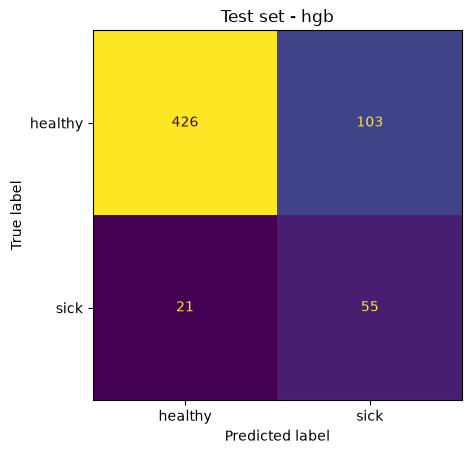

In [16]:
# only run this once we're done tuning!
test_set = pd.read_parquet("test_set.parquet")
X_test = test_set.drop(columns=TARGET_COL)
y_test = test_set[TARGET_COL].copy()

test_preds = final_model.predict(X_test)
print(f"F2:        {fbeta_score(y_test, test_preds, beta=2):.3f}")
print(f"recall:    {recall_score(y_test, test_preds):.3f}")
print(f"precision: {precision_score(y_test, test_preds):.3f}")
print()
print(classification_report(y_test, test_preds, target_names=["healthy", "sick"]))
ConfusionMatrixDisplay.from_predictions(y_test, test_preds, display_labels=["healthy", "sick"], colorbar=False)
plt.title(f"Test set - {best_name}")
plt.show()

- On the test set we got recall 0.724 and F2 0.595. Recall went up from 0.684 (before the gray threshold), but F2 went down since we're trading precision for recall now (0.35 vs 0.45).
- That means we catch 55 of the 76 sick squirrels and miss 21. We also get about 103 false alarms, up from 63.
- The gray threshold only got us 3 more sick squirrels on the test set, which is less than CV made it look. The test set only has 76 sick squirrels though, so it's hard to tell from such a small number.
- This still probably isn't good enough for the client, since they wanted recall as close to 100% as possible. Missing about 1 in 4 sick squirrels is still a lot for a disease this contagious.

Going forward, we could lower the gray threshold even more, but it gets expensive really fast (see the gray section in Presentation). It seems like the real fix would be better data for gray squirrels.